# Verarbeitung und Darstellung der Messdaten


## Import all libraries and load data as pandas dataframe


In [1]:
#import libraries
import pandas as pd
import numpy as np
import scipy.signal as sci
import matplotlib.pyplot as plot

In [3]:
#import recorded .csv Files and store them in a dataframe
df = pd.read_csv('data\IMU.csv', sep=';')

#convert time from ms into s
df['Time'] = df['Time'].div(1000)


<>:2: SyntaxWarning: "\I" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\I"? A raw string is also an option.
<>:2: SyntaxWarning: "\I" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\I"? A raw string is also an option.
C:\Users\pfust\AppData\Local\Temp\ipykernel_17480\4027639286.py:2: SyntaxWarning: "\I" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\I"? A raw string is also an option.
  df = pd.read_csv('data\IMU.csv', sep=';')


FileNotFoundError: [Errno 2] No such file or directory: 'data\\IMU.csv'

<Axes: title={'center': 'Accelerometer Test'}, xlabel='Time in s', ylabel='Acceleration in g'>

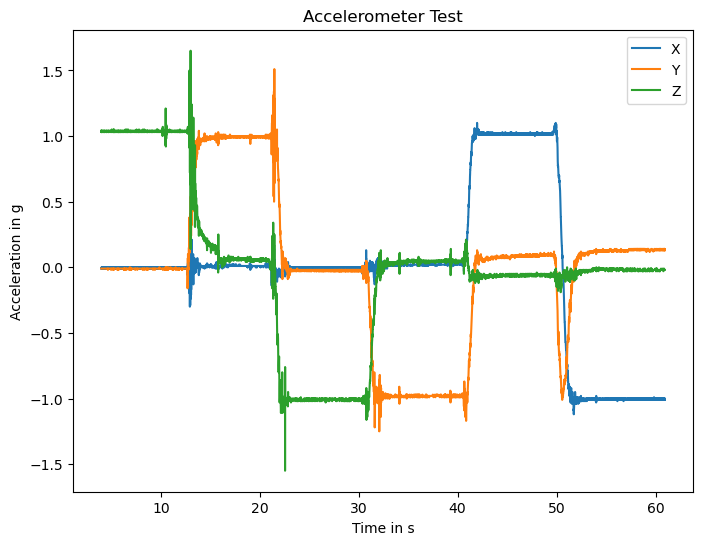

In [3]:
# display data
df.plot(x = 'Time', y = ['X', 'Y', 'Z'], ylabel='Acceleration in g', 
        xlabel='Time in s', figsize= [8, 6], title="Accelerometer Test")


# Filter acceleration data applying different filter techniques
## Bandpass filter (Butterworth 4. order)

Wir möchten einen Filter verwende, der das Signal nicht verschiebt, demnach einen zero-Phase Filter. Scipy bietet diese Option mit der _filtfilt()_ Methode an. Dieser verwendet zwei _Infinite Impuls Response_ Filter hintereinander geschaltet, jedoch wird der erste vorwärts und der zweite rückwärts angewandt, um keine Phasenverschiebung zu erhalten.

Dies ist auch in folgender Abbildung zu erkennen. Die gestrichelte rote Line stellt einen Filter dar, welcher das Signal filtert und störende Frequenzen entfernt, jedoch ist dieser um eine Phase verschoben zum eigentlichen Signal. Die rote Line ist die zweite Anwendung des Filters. Würde man den zweiten Filter jedoch rückwärts anwenden, würde man die schwarze Linie und somit das Ergebnis der _filtfilt()_ methode erhalten.



![Unterschied zwischen verschiedenen Filtertypen](bilder/zeroPhase.png)

In [4]:
# Setting up a butterworth filter 

def butter_bandpass(lowcut,fs,order):
    
    # nyq: Nyquist Theorem
    nyq = 0.5 * fs
    # low is calculated in relation to cutoff frequency and sampling frequency
    low = lowcut / nyq
    
    order = 4
    
    b, a = sci.butter(order, [low], 'lowpass', analog=False)
    
    return b, a



In [5]:
def butter_bandpass_filter(signal, lowcut, fs, order):
    #use filtfilt for a zero-phase filtering
    b, a = butter_bandpass(lowcut,fs, order)
    y = sci.filtfilt(b, a, signal, axis = 0, order=order)
    return y